# 5-1(참고) — 변수별 차분(d,D) 비교

## 목적

6개 변수 각각에 대해 **같은 모델(Auto-ARIMA)** 로 차분만 4가지(무차분/1차차분/계절차분/둘다)로
바꿔가며 walk-forward CRPS를 비교한다. p,q(+P,Q)는 매번 AIC로 자동 최적화하고, d,D만 강제 고정해서
"차분 선택 자체의 효과"만 순수하게 비교한다.

## 방법
- `pm.auto_arima(values, d=고정, D=고정, seasonal=(D>0), m=4)` — 4가지 설정
- 결정기준(AIC, in-sample)이 아니라 **walk-forward 실측 CRPS(out-of-sample)** 로 비교


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}
H = 4
MIN_TRAIN = 20
INITIAL_CALIB = 15

CONFIGS = [(0, 0), (1, 0), (0, 1), (1, 1)]
CONFIG_LABELS = {(0, 0): "기본(무차분)", (1, 0): "1차차분", (0, 1): "계절차분", (1, 1): "둘다(1차+계절)"}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)

def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

def fc_arima_fixed(values, h, d, D):
    seasonal = D > 0
    kwargs = dict(seasonal=seasonal, suppress_warnings=True, error_action="ignore", d=d)
    if seasonal:
        kwargs.update(m=4, D=D)
    m = pm.auto_arima(values, **kwargs)
    return np.asarray(m.predict(n_periods=h))

print("준비 완료 -- 6개 변수 x 4개 차분설정 백테스트를 시작한다 (시간이 좀 걸릴 수 있음)")


준비 완료 -- 6개 변수 x 4개 차분설정 백테스트를 시작한다 (시간이 좀 걸릴 수 있음)


### 4가지 설정의 실제 파라미터 값

| 설정 | d(1차차분) | D(계절차분) | seasonal | m |
|---|---|---|---|---|
| 기본(무차분) | 0 | 0 | False | - |
| 1차차분 | **1** | 0 | False | - |
| 계절차분 | 0 | **1** | True | 4 |
| 둘다(1차+계절) | **1** | **1** | True | 4 |

`d`는 `pm.auto_arima`에 항상 넘기고, `D`는 계절차분이 있는 설정(2개)에서만 `m=4`(분기데이터라
계절주기=4)와 함께 넘긴다. p,q(계절이면 P,Q까지)는 4가지 설정 전부 AIC로 자동 최적화된다.


## 1. 6개 변수 x 4개 차분설정 walk-forward 백테스트


In [2]:
import time
t0 = time.time()
records = []
for v in COLS:
    vals = raw[["quarter", v]].dropna()[v].values.astype(float)
    n = len(vals)
    for origin in range(MIN_TRAIN, n - H + 1):
        train, actual = vals[:origin], vals[origin:origin + H]
        for (d, D) in CONFIGS:
            name = CONFIG_LABELS[(d, D)]
            try:
                fc = fc_arima_fixed(train, H, d, D)
            except Exception:
                fc = np.repeat(train[-1], H)
            err = actual - fc
            for h in range(1, H + 1):
                records.append({"var": v, "model": name, "origin": origin, "h": h,
                                 "err_t": err[h - 1], "fc_t": fc[h - 1], "actual_orig": actual[h - 1]})
    print(f"{LABELS[v]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)
print(f"총 소요 {time.time()-t0:.0f}초, {len(err_df)}행")


X1 완료 (227초 경과)


X2 완료 (1027초 경과)


X3 완료 (1381초 경과)


X4 완료 (2107초 경과)


X5 완료 (2554초 경과)


X6 완료 (3047초 경과)
총 소요 3047초, 3568행


## 2. 변수별 CRPS 비교


In [3]:
def crps_score_for(var, model_name, n_samples=500):
    rng = rng_for(model_name + var)
    e = err_df[(err_df["model"] == model_name) & (err_df["var"] == var)]
    origins = sorted(e["origin"].unique())
    var_std = e["actual_orig"].std()
    scores = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = e[e["origin"].isin(origins[:i])]
        test = e[e["origin"] == origins[i]]
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h, size=n_samples, replace=True)
            scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std)
    return np.mean(scores)

rows = []
for v in COLS:
    row = {"변수": LABELS[v]}
    for cfg in CONFIGS:
        row[CONFIG_LABELS[cfg]] = round(crps_score_for(v, CONFIG_LABELS[cfg]), 4)
    rows.append(row)
result_df = pd.DataFrame(rows).set_index("변수")
display(result_df)

best_per_var = result_df.idxmin(axis=1)
print("\n변수별 최선 설정:")
for v_label, best in best_per_var.items():
    print(f"  {v_label}: {best} (CRPS={result_df.loc[v_label, best]})")


,기본(무차분),1차차분,계절차분,둘다(1차+계절)
변수,,,,
X1,0.6645,0.9003,0.8012,1.0300
X2,0.5339,0.5973,0.6065,0.6626
X3,0.5248,0.5300,0.6547,0.6792
X4,0.5122,0.5908,0.6121,0.6210
X5,0.6985,0.7933,1.0336,1.2873
X6,0.2554,0.2210,0.2460,0.2528



변수별 최선 설정:
  X1: 기본(무차분) (CRPS=0.6645)
  X2: 기본(무차분) (CRPS=0.5339)
  X3: 기본(무차분) (CRPS=0.5248)
  X4: 기본(무차분) (CRPS=0.5122)
  X5: 기본(무차분) (CRPS=0.6985)
  X6: 1차차분 (CRPS=0.221)


## 3. 그래프로 비교 (변수별 4개 막대, 최선 설정 강조)


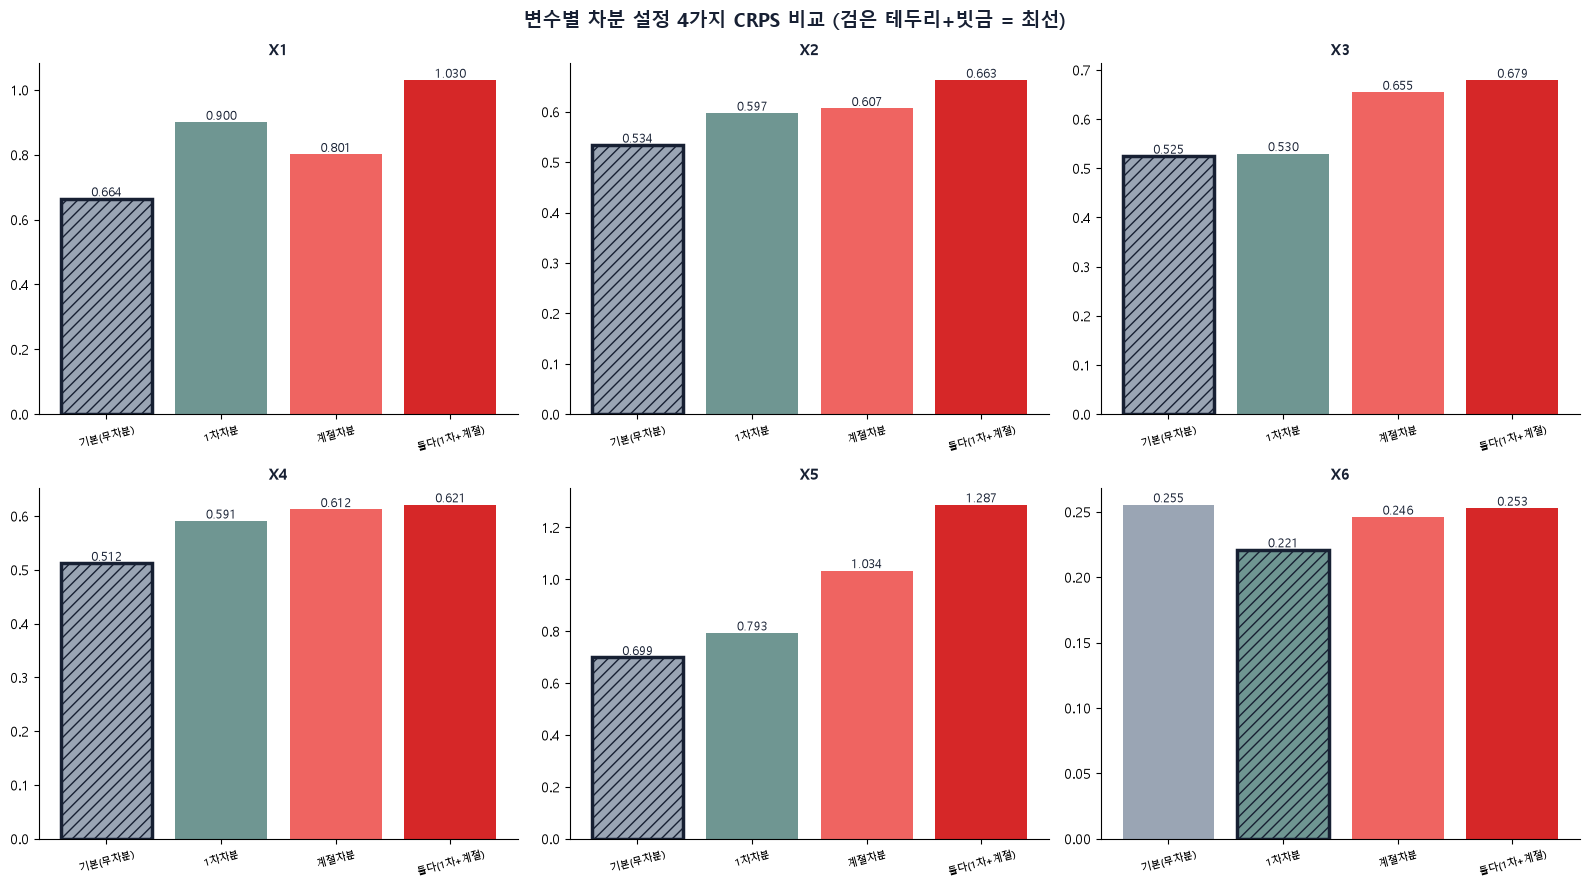

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colors_map = {"기본(무차분)": "#9AA5B4", "1차차분": "#6F9692", "계절차분": "#EF6461", "둘다(1차+계절)": "#D62728"}
for ax, v in zip(axes.flat, COLS):
    v_label = LABELS[v]
    vals_ = [result_df.loc[v_label, CONFIG_LABELS[c]] for c in CONFIGS]
    labels_ = [CONFIG_LABELS[c] for c in CONFIGS]
    colors_ = [colors_map[l] for l in labels_]
    bars = ax.bar(labels_, vals_, color=colors_)
    best_idx = int(np.argmin(vals_))
    bars[best_idx].set_edgecolor("#172033")
    bars[best_idx].set_linewidth(2.5)
    bars[best_idx].set_hatch("///")
    for bar, val in zip(bars, vals_):
        ax.text(bar.get_x() + bar.get_width() / 2, val, f"{val:.3f}", ha="center", va="bottom", fontsize=8.5, color="#172033")
    ax.set_title(v_label, fontsize=11, fontweight="bold", color="#172033")
    ax.set_xticklabels(labels_, fontsize=7.5, rotation=15)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("변수별 차분 설정 4가지 CRPS 비교 (검은 테두리+빗금 = 최선)", fontsize=14, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


## 결론

`idxmin`으로 뽑은 변수별 최선 차분 설정을 위 표/그래프에서 바로 확인할 수 있다 -- 5-1의 최종 AutoML
선정 결과(어떤 모델을 쓸지)와는 별개로, "그 변수에 차분을 어떻게 적용하는 게 유리한가"에 대한
참고 자료다.
